I0000 00:00:1792906926.847264  129989 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792906926.874047  129989 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792906928.220793  129989 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/home/mckb/Git/College/DL/.venv/lib/python3.14/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1792906930.302612  129989 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: 

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9132 - loss: 0.2975 - val_accuracy: 0.9468 - val_loss: 0.1732
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9601 - loss: 0.1332 - val_accuracy: 0.9675 - val_loss: 0.1059
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9743 - loss: 0.0860 - val_accuracy: 0.9756 - val_loss: 0.0768


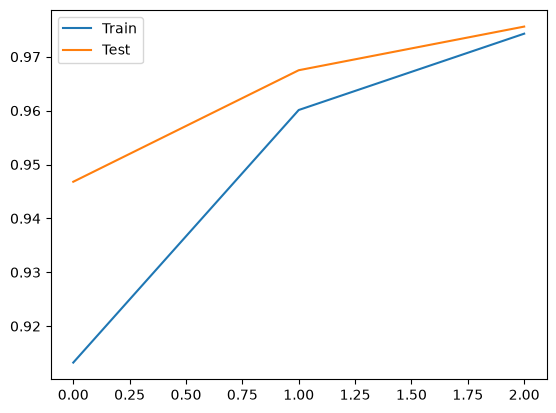

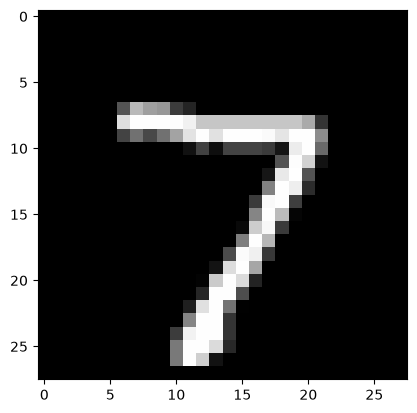

Prediction: 7
True label: 7


In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras import layers,models

(x_train,y_train),(x_test,y_test) = tf.keras.datasets.mnist.load_data()


x_train = x_train[...,None]/255.0
x_test = x_test[...,None]/255.0

model = models.Sequential([
    layers.Conv2D(8,3,activation='relu',input_shape=(28,28,1)),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(32,activation='relu'),
    layers.Dense(10,activation='softmax')])

model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history = model.fit(x_train,y_train,epochs=3,validation_data=(x_test,y_test))

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Test'])
plt.show()

plt.imshow(x_test[0].reshape(28,28),cmap='gray'); plt.show()
prediction = model.predict(x_test[:1],verbose=0)
print("Prediction:",np.argmax(prediction))
print("True label:",y_test[0])
